# 인덱싱 비교 실험

**이 노트북에서 할 일**

1. 말뭉치 PDF 18건을 읽어 쪽마다 Document를 만듭니다.
2. 나누기 설정을 하나씩 바꿔 색인을 여섯 벌 만듭니다.
3. 같은 질문으로 검색해 결과를 여섯 줄 기록으로 남깁니다.

**준비물** — 프로젝트 맨 위 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 모두 열세 번이고, 답을 쓰는 모델은 부르지 않습니다.
보낼 조각 수는 390970개 어림입니다.

예상 비용은 열세 번을 합쳐 0.01달러 미만입니다.
임베딩 요금은 OpenAI 모델 안내(2026-09-17 확인)에 적힌 100만 토큰당 0.02달러입니다.
실행 시간은 패키지 설치를 빼면 2분 안팎입니다.

데이터는 두 갈래입니다.
폴더 `labs/data/rag-corpus/pdf/`의 디지털 PDF 18건을 읽습니다.
질문과 정답 문서 ID는 폴더 `labs/part3/ch11-evaluation/data/`의 평가셋에서 읽습니다.

기록은 폴더 `labs/part3/ch10-document-processing/runs/`에 씁니다.
최신 기록 파일 한 개와 실행별 사본 여섯 개가 생깁니다.
이 파일은 Ch 11이 읽는 입력이라 칸 이름과 줄 수를 바꾸지 않습니다.

**강의와 실습 범위** — 강의 시간에는 4~7절을 설명합니다.
실험 격자 만들기, 조각 수 어림하기, 색인 만들고 검색하기, 여섯 결과 읽기입니다.
8절 값 바꿔 보기와 9절 기록 남기기는 함께 실행하고 실습 시간에 다시 읽습니다.
2절은 01·05절과 같은 코드라 강의에서 빠르게 확인합니다.

**기준 버전** — 실습 폴더에 고정한 패키지 판을 씁니다.
pypdf 6.18.0과 langchain-core 1.6.2를 씁니다.
나누기 도구는 langchain-text-splitters 1.1.2입니다.
임베딩은 langchain-openai 1.6.0으로 부릅니다.
조각은 tiktoken 0.14.0으로 셉니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch10-document-processing`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

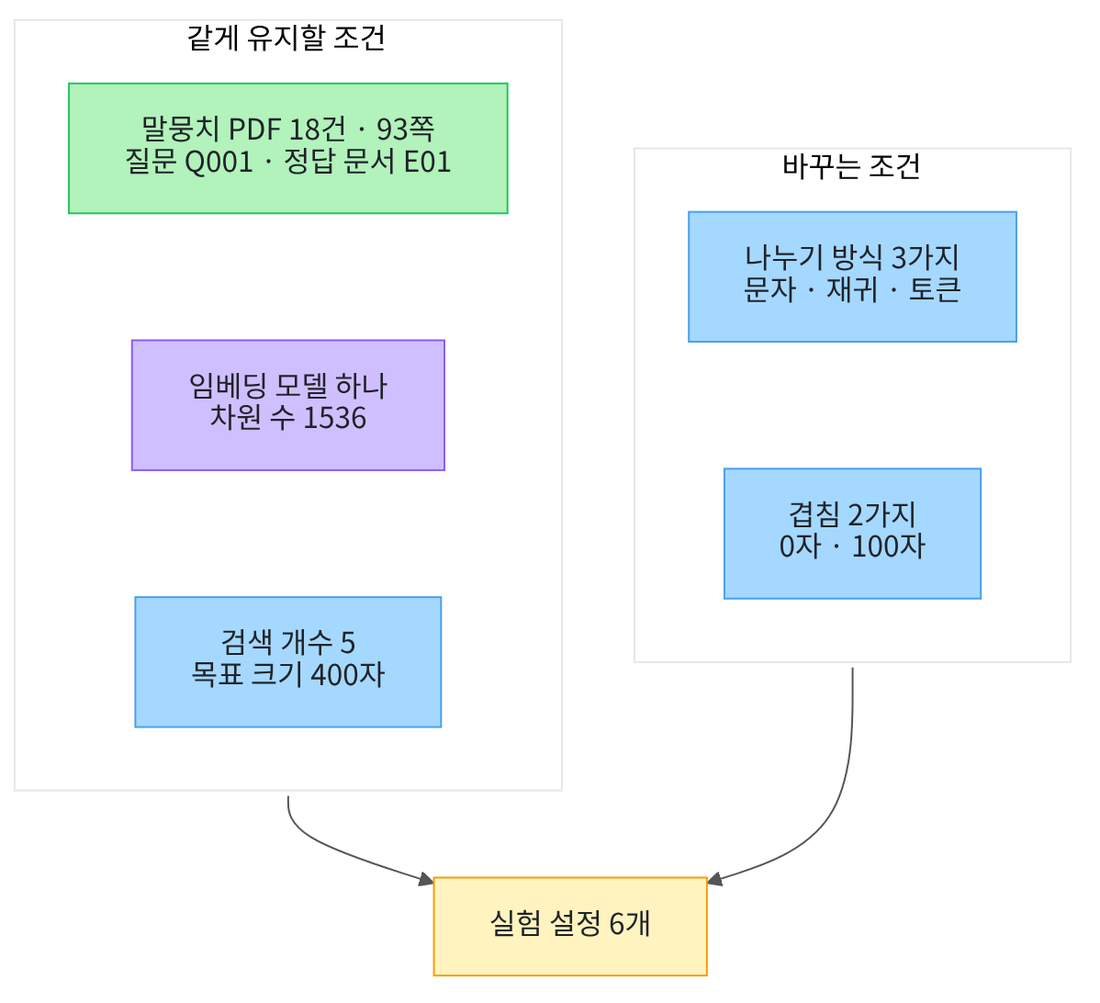

왼쪽 칸과 오른쪽 칸을 견주고 아래로 내려갑니다.
왼쪽 칸은 여섯 설정에서 모두 같게 두는 조건입니다.
오른쪽 칸은 하나씩 바꾸는 조건입니다.
두 칸을 곱해 실험 설정 여섯 개가 나옵니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.
01·05·07절에서 쓴 도구를 그대로 씁니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "pypdf==6.18.0" "langchain-core==1.6.2" "langchain-text-splitters==1.1.2" "langchain-openai==1.6.0" "tiktoken==0.14.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("pypdf:", version("pypdf"))
print("langchain-core:", version("langchain-core"))
print("langchain-text-splitters:", version("langchain-text-splitters"))
print("langchain-openai:", version("langchain-openai"))
print("tiktoken:", version("tiktoken"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
pypdf: 6.18.0
langchain-core: 1.6.2
langchain-text-splitters: 1.1.2
langchain-openai: 1.6.0
tiktoken: 0.14.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 여섯 줄 가운데 첫 줄은 `pypdf: 6.18.0`입니다.
셋째 줄 `langchain-text-splitters: 1.1.2`와 넷째 줄 `langchain-openai: 1.6.0`도 보세요.
준비물에 적은 기준 버전과 같습니다.

다음 셀은 이 절에서 쓸 이름을 불러옵니다.
클래스 `CharacterTextSplitter`와 `RecursiveCharacterTextSplitter`가 05절에서 쓴 나누기 도구입니다.
클래스 `InMemoryVectorStore`가 Ch 9 03절에서 쓴 색인이고 `OpenAIEmbeddings`가 임베딩을 부릅니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 9 02절 `load_pdf_pages()`와 Ch 8 01절 `count_tokens()`를 가져옵니다.

In [2]:
# 나누기·임베딩·색인·조각 세기·기록 저장에 쓸 이름을 불러옵니다
import hashlib
import json
import os
import time

from langchain_core.vectorstores import InMemoryVectorStore
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import CharacterTextSplitter
from langchain_text_splitters import RecursiveCharacterTextSplitter
import tiktoken
# Ch 9 02절과 Ch 8 01절 함수 두 개를 도구 파일에서 가져옵니다
from rag_tools import count_tokens, load_pdf_pages

**결과 읽기** — 이 셀은 이름을 불러오기만 하므로 출력이 없습니다.

모듈 `time`은 Python에 들어 있는 기능 묶음입니다.
이 절에서는 실행 이름에 넣을 날짜와 시각을 만드는 데 씁니다.
Ch 9 06절에서 실행 이름을 만들 때 쓴 것과 같은 모듈입니다.

다음 셀은 키가 있는지 확인합니다. 키 값은 출력하지 않고 있는지만 봅니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True`입니다.

## 2. 말뭉치 18건 읽기

01~07절과 같은 방법으로 프로젝트 맨 위 경로를 고릅니다.
후보 세 개를 차례로 확인하고, 있는 경로에서 멈춥니다.

실행 전에 예상합니다. 프로젝트 맨 위에서 열었다면 첫째 후보를 고를 것입니다.

In [4]:
# 작업 폴더에서 본 프로젝트 맨 위 경로를 후보 세 개 가운데에서 고릅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/data/rag-corpus"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: ../../../..


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.
교재 출력은 프로젝트 맨 위를 작업 폴더로 삼아 실행해서 첫째 후보를 골랐습니다.

다음 셀은 말뭉치 목록 파일을 읽어 디지털 PDF만 골라 둡니다.
01절에서 본 네 갈래 가운데 `scanned`는 글자 층이 없는 스캔 변형이라 뺍니다.
Ch 9 06절 색인과 같은 18건을 쓰려는 것입니다.

In [5]:
# 말뭉치 목록에서 스캔 변형을 빼고 디지털 PDF 18건만 골라 둡니다
corpus_path = root_path + "/labs/data/rag-corpus"
manifest_path = corpus_path + "/manifest.json"
with open(manifest_path, encoding="utf-8") as manifest_file:
    manifest_rows = json.loads(manifest_file.read())
digital_rows = []
for row in manifest_rows:
    if row["tier"] != "scanned":
        digital_rows.append(row)
print("목록의 전체 행 수:", len(manifest_rows))
print("디지털 PDF 수:", len(digital_rows))
print("첫 문서의 이름과 쪽 수:", digital_rows[0]["doc_id"], digital_rows[0]["pages"])

목록의 전체 행 수: 21
디지털 PDF 수: 18
첫 문서의 이름과 쪽 수: E01 5


**결과 읽기** — 출력 첫 줄은 `목록의 전체 행 수: 21`입니다.
다음 줄 `디지털 PDF 수: 18`이 이 절이 색인에 넣을 문서 수입니다.
셋째 줄은 `첫 문서의 이름과 쪽 수: E01 5`이고 01~07절에서 읽은 그 문서입니다.

목록에서 뺀 세 건은 스캔 변형입니다. 02절에서 글자 층이 비는 것을 확인한 파일입니다.

준비 셀에서 가져온 Ch 9 02절 로더 함수 `load_pdf_pages()`로 문서를 읽습니다.

다음 셀은 이 함수로 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다.
01~07절은 문서 하나만 읽었습니다. 여러 문서를 한 번에 읽는 것은 이 절이 처음입니다.

In [6]:
# 디지털 PDF 18건을 차례로 읽어 쪽 Document를 한 목록에 모읍니다
corpus_pages = []
for row in digital_rows:
    file_path = corpus_path + "/" + row["file"]
    row_pages = load_pdf_pages(file_path, row["doc_id"])
    for page_document in row_pages:
        corpus_pages.append(page_document)
print("읽은 문서 수:", len(digital_rows))
print("읽은 쪽 수:", len(corpus_pages))
print("첫 쪽의 메타데이터:", corpus_pages[0].metadata)

읽은 문서 수: 18
읽은 쪽 수: 93
첫 쪽의 메타데이터: {'doc_id': 'E01', 'page': 1, 'source': 'E01.pdf'}


**결과 읽기** — 출력 첫 줄은 `읽은 문서 수: 18`이고 다음 줄은 `읽은 쪽 수: 93`입니다.
셋째 줄 `첫 쪽의 메타데이터: {'doc_id': 'E01', 'page': 1, 'source': 'E01.pdf'}`를 보세요.
01절에서 정한 칸 이름을 그대로 씁니다.

Ch 9 06절도 같은 18건에서 93쪽을 읽었습니다. 같은 파일을 같은 파서로 읽었기 때문입니다.

다음 셀은 본문 글자 수가 0인 쪽을 세고, 글이 있는 문서가 몇 건인지 셉니다.

In [7]:
# 본문 글자 수가 0인 쪽을 모으고 글이 있는 문서 이름을 따로 셉니다(02절 글자 층)
empty_page_docs = []
text_doc_ids = []
for page_document in corpus_pages:
    if len(page_document.page_content) == 0:
        empty_page_docs.append(page_document.metadata["doc_id"])
    elif page_document.metadata["doc_id"] not in text_doc_ids:
        text_doc_ids.append(page_document.metadata["doc_id"])
print("글자 층이 빈 쪽 수:", len(empty_page_docs))
print("그 쪽의 문서 이름:", empty_page_docs)
print("글이 있는 문서 수:", len(text_doc_ids))

글자 층이 빈 쪽 수: 3
그 쪽의 문서 이름: ['H05', 'H05', 'H05']
글이 있는 문서 수: 17


**결과 읽기** — 출력 첫 줄은 `글자 층이 빈 쪽 수: 3`입니다.
다음 줄 `그 쪽의 문서 이름: ['H05', 'H05', 'H05']`를 보세요. 한 문서의 세 쪽입니다.
셋째 줄은 `글이 있는 문서 수: 17`입니다.

말뭉치 목록은 이 문서를 「텍스트 레이어가 없는 스캔 이미지」라고 적어 두었습니다.
그 목록이 쓴 「텍스트 레이어」가 02절에서 정한 글자 층입니다.
`scanned` 갈래가 아니라 `hard` 갈래에 들어 있어 앞의 18건에 함께 딸려 왔습니다.
나눌 글이 없는 쪽은 문서 청크가 되지 않아 색인에는 문서 17건만 들어갑니다.

## 3. 질문과 정답 문서 가져오기

Ch 9 06절과 같은 방법으로 Ch 11 평가셋에서 질문을 읽습니다.
질문 글과 정답 문서 ID를 노트북에 적지 않고 파일에서 읽는 까닭이 있습니다.
기록을 읽는 쪽이 두 값을 평가셋과 글자까지 대조하기 때문입니다.

In [8]:
# Ch 11 평가셋 파일을 줄 단위로 읽습니다
query_path = root_path + "/labs/part3/ch11-evaluation/data/evaluation-queries.jsonl"
with open(query_path, encoding="utf-8") as query_file:
    query_lines = query_file.read().splitlines()
print("평가셋의 줄 수:", len(query_lines))

평가셋의 줄 수: 30


**결과 읽기** — 출력 줄은 `평가셋의 줄 수: 30`입니다.
한 줄이 질문 하나입니다. 이 절은 그 가운데 하나만 씁니다.

다음 셀은 질문 번호 `Q001`인 줄을 찾아 질문 글과 정답 문서 ID를 꺼냅니다.

In [9]:
# 질문 번호 Q001인 줄을 찾아 질문 글과 정답 문서 ID를 꺼냅니다
query_row = None
for line in query_lines:
    row = json.loads(line)
    if row["qid"] == "Q001":
        query_row = row
        break
question_text = query_row["question"]
gold_doc_ids = query_row["gold_doc_ids"]
print("질문 번호:", query_row["qid"])
print("질문:", question_text)
print("정답 문서 ID:", gold_doc_ids)

질문 번호: Q001
질문: 미르시립도서관의 정기 휴관일은 언제인가요?
정답 문서 ID: ['E01']


**결과 읽기** — 출력 첫 줄은 `질문 번호: Q001`입니다.
다음 줄은 `질문: 미르시립도서관의 정기 휴관일은 언제인가요?`입니다.
셋째 줄 `정답 문서 ID: ['E01']`이 이 질문의 정답 문서입니다.

Ch 9 06절이 쓴 질문과 같은 글입니다. 05·06·07절이 읽은 `E01.pdf`가 그 정답 문서입니다.
정답은 문서 단위입니다. 몇 쪽인지는 이 파일에 없습니다.

## 4. 실험 격자 만들기

이제 바꿀 조건을 정합니다. 05절에서 배운 세 나누기 방식과 겹침 두 값입니다.
세 방식을 두 겹침과 짝지으면 설정 여섯 개가 나옵니다.

목표 크기는 여섯 설정 모두 400자로 둡니다.
크기까지 함께 바꾸면 어느 조건이 결과를 바꿨는지 가를 수 없습니다.

첫 셀은 문자 방식 설정 두 개를 만듭니다.
설정마다 나누기 값 딕셔너리와 스플리터를 함께 담습니다.

In [10]:
# 문자 방식 설정 두 개를 만듭니다(겹침 0자와 100자)
chunk_target = 400
overlap_values = [0, 100]
separator_order = ["\n\n", ". ", "\n", " ", ""]
settings = []
for chunk_overlap in overlap_values:
    char_config = {"separator": "\n", "chunk_size": chunk_target, "chunk_overlap": chunk_overlap}
    char_splitter = CharacterTextSplitter(
        separator="\n", chunk_size=chunk_target, chunk_overlap=chunk_overlap,
    )
    settings.append({"chunk_method": "char", "split_config": char_config, "splitter": char_splitter})
print("설정 수:", len(settings))
print("문자 방식 첫 설정:", settings[0]["split_config"])

설정 수: 2
문자 방식 첫 설정: {'separator': '\n', 'chunk_size': 400, 'chunk_overlap': 0}


**결과 읽기** — 출력 첫 줄은 `설정 수: 2`입니다.
다음 줄 `문자 방식 첫 설정: {'separator': '\n', 'chunk_size': 400, 'chunk_overlap': 0}`을 보세요.
05절 3절과 같은 경계 한 개를 쓰고 목표 크기만 400자로 바꿨습니다.

칸 `splitter`에는 나누는 도구가 들어 있어 출력에 적지 않았습니다.
기록 파일에는 이 칸을 넣지 않고 `split_config`만 넣습니다.

다음 셀은 재귀 방식 설정 두 개를 더합니다.

In [11]:
# 재귀 방식 설정 두 개를 더합니다(05절 4절과 같은 끊을 자리 순서)
for chunk_overlap in overlap_values:
    recursive_config = {"separators": separator_order, "chunk_size": chunk_target,
                        "chunk_overlap": chunk_overlap}
    recursive_splitter = RecursiveCharacterTextSplitter(
        separators=separator_order, chunk_size=chunk_target,
        chunk_overlap=chunk_overlap, keep_separator="end",
    )
    settings.append({"chunk_method": "recursive", "split_config": recursive_config,
                     "splitter": recursive_splitter})
print("설정 수:", len(settings))
print("재귀 방식의 끊을 자리 순서:", settings[2]["split_config"]["separators"])

설정 수: 4
재귀 방식의 끊을 자리 순서: ['\n\n', '. ', '\n', ' ', '']


**결과 읽기** — 출력 첫 줄은 `설정 수: 4`입니다.
다음 줄 `재귀 방식의 끊을 자리 순서: ['\n\n', '. ', '\n', ' ', '']`을 보세요.
05절 4절에서 쓴 순서 그대로입니다.

다음 셀은 토큰 방식 설정 두 개를 더해 여섯 개를 채웁니다.

In [12]:
# 토큰 방식 설정 두 개를 더합니다(05절 10절과 같은 조각 세는 규칙)
encoding_name = "cl100k_base"
for chunk_overlap in overlap_values:
    token_config = {"encoding_name": encoding_name, "separators": separator_order,
                    "chunk_size": chunk_target, "chunk_overlap": chunk_overlap}
    token_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
        encoding_name=encoding_name, separators=separator_order,
        chunk_size=chunk_target, chunk_overlap=chunk_overlap, keep_separator="end",
    )
    settings.append({"chunk_method": "token", "split_config": token_config,
                     "splitter": token_splitter})
print("설정 수:", len(settings))
print("토큰 방식 둘째 설정의 겹침:", settings[5]["split_config"]["chunk_overlap"])

설정 수: 6
토큰 방식 둘째 설정의 겹침: 100


**결과 읽기** — 출력 첫 줄은 `설정 수: 6`입니다.
다음 줄은 `토큰 방식 둘째 설정의 겹침: 100`입니다. 여섯 설정이 모두 만들어졌습니다.

목록 순서는 문자 0자, 문자 100자, 재귀 0자, 재귀 100자, 토큰 0자, 토큰 100자입니다.
토큰 방식의 400과 100은 문자 수가 아니라 조각 수입니다.
05절에서 본 대로 이 말뭉치는 문자 수와 조각 수가 비슷해 크기도 비슷하게 나옵니다.

## 5. 보낼 조각 수와 비용 어림하기

요청을 보내기 전에 몇 조각을 보낼지 어림합니다.
06·07절과 같은 방식입니다. 색인 여섯 벌이니 말뭉치 전체를 여섯 번 보냅니다.

겹침을 준 설정은 같은 글이 두 번 담기는 자리가 있어 조각이 조금 늘어납니다.
그 몫을 1.1배로 잡습니다.

첫 셀은 조각 세는 규칙을 준비합니다. 조각 수는 준비 셀에서 가져온 `count_tokens()`로 셉니다.

In [13]:
# 4절에서 정한 이름으로 조각 세는 규칙을 불러옵니다
encoding = tiktoken.get_encoding(encoding_name)
print("조각 세는 규칙 이름:", encoding.name)

조각 세는 규칙 이름: cl100k_base


**결과 읽기** — 출력 줄은 `조각 세는 규칙 이름: cl100k_base`입니다.
4절에서 정한 이름이고, 토큰 방식 스플리터도 같은 규칙으로 글을 셉니다.

다음 셀은 말뭉치 전체의 조각 수를 세고 비용을 어림합니다.

In [14]:
# 말뭉치 전체의 조각 수를 세고 여섯 설정이 보낼 조각 수와 비용을 어림합니다
corpus_tokens = 0
for page_document in corpus_pages:
    corpus_tokens = corpus_tokens + count_tokens(encoding, page_document.page_content)
overlap_times = 1.1
sent_tokens = int(corpus_tokens * len(settings) * overlap_times)
embedding_rate = 0.02
tokens_per_million = 1000000
total_cost = round(sent_tokens / tokens_per_million * embedding_rate, 7)
print("말뭉치 전체의 조각 수:", corpus_tokens)
print("여섯 설정이 보낼 조각 수 어림:", sent_tokens)
print("이 절 전체의 비용 어림(달러):", total_cost)

말뭉치 전체의 조각 수: 59238
여섯 설정이 보낼 조각 수 어림: 390970
이 절 전체의 비용 어림(달러): 0.0078194


**결과 읽기** — 출력 첫 줄은 `말뭉치 전체의 조각 수: 59238`입니다.
다음 줄 `여섯 설정이 보낼 조각 수 어림: 390970`이 색인 여섯 벌의 어림입니다.
셋째 줄은 `이 절 전체의 비용 어림(달러): 0.0078194`입니다.

요금은 100만 조각당 0.02달러로 잡았습니다. 코드로 센 어림이고 청구 금액이 아닙니다.
질문을 보내는 요청은 조각 수가 적어 어림에서 뺐습니다.

## 6. 색인 만들고 검색하기

임베딩 모델은 Ch 9 03절·06절·07절과 같은 이름으로 하나만 씁니다.
차원 수는 주지 않아 그 모델의 기본값입니다. 07절에서 본 대로 숫자 1536개입니다.

검색 개수는 5로 둡니다. 기록에 남길 줄 수도 그 값입니다.
Ch 9 06절은 2를 썼습니다. 둘을 다르게 둔 까닭은 9절에서 봅니다.

In [15]:
# Ch 9·06·07절과 같은 임베딩 모델을 기본 설정으로 준비합니다(이 셀은 요청을 보내지 않습니다)
embedding_model_name = "text-embedding-3-small"
embedding_model = OpenAIEmbeddings(model=embedding_model_name)
search_count = 5
print("임베딩 모델 이름:", embedding_model_name)
print("차원 수를 주었는가:", embedding_model.dimensions is not None)
print("검색 개수:", search_count)

임베딩 모델 이름: text-embedding-3-small
차원 수를 주었는가: False
검색 개수: 5


**결과 읽기** — 출력 첫 줄은 `임베딩 모델 이름: text-embedding-3-small`입니다.
다음 줄 `차원 수를 주었는가: False`는 인자 `dimensions`를 주지 않았다는 뜻입니다.
셋째 줄은 `검색 개수: 5`입니다.

07절에서 만든 숫자 256개짜리 벡터는 여기에 쓰지 않습니다.
숫자 개수가 다른 벡터를 한 색인에 섞으면 검색 점수를 계산할 수 없습니다.

다음 셀은 문서 청크마다 이름을 붙이는 함수를 만듭니다.
메서드 `zfill()`은 글 앞에 0을 채워 글자 수를 맞춥니다.

In [16]:
# 문서 청크마다 이름을 붙입니다(ch10 · 방식 이름 · 네 자리 번호)
def name_chunks(chunk_documents, method):
    number = 0
    for chunk in chunk_documents:
        chunk.metadata["chunk_id"] = "ch10:" + method + ":" + str(number).zfill(4)
        number = number + 1
    return chunk_documents

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 값을 출력하지 않습니다.

이름은 `ch10:recursive:0000` 모양입니다. 설정 안에서 몇 번째 문서 청크인지 적습니다.
Ch 9 06절 기록의 이름은 `ch09:6f9f83db90:0` 모양이라 가운데와 번호 모양이 다릅니다.
기록을 읽는 쪽은 이 칸이 빈 값인지만 보므로 모양이 달라도 됩니다.

다음 셀은 설정 하나를 받아 색인을 만들고 검색까지 하는 함수를 만듭니다.

In [17]:
# 설정 하나로 색인을 만들고 질문으로 검색해 결과를 모아 반환합니다(임베딩 요청 2번)
def run_setting(setting):
    chunk_documents = setting["splitter"].split_documents(corpus_pages)
    name_chunks(chunk_documents, setting["chunk_method"])
    store = InMemoryVectorStore(embedding=embedding_model)
    store.add_documents(chunk_documents)
    hits = store.similarity_search_with_score(question_text, k=search_count)
    top_document = hits[0][0]
    vector_size = len(store.store[top_document.id]["vector"])
    return {"chunk_count": len(chunk_documents), "hits": hits,
            "vector_size": vector_size, "store": store}

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

함수 안에서 하는 일은 네 가지입니다.
말뭉치를 그 설정으로 나누고, 문서 청크에 이름을 붙이고, 색인에 넣고, 질문으로 검색합니다.
벡터의 숫자 개수는 색인에 든 저장 항목에서 직접 셉니다. Ch 9 03절에서 쓴 모양입니다.

다음 셀이 이 절에서 요청을 보내는 자리입니다.
여섯 설정을 차례로 실행하므로 임베딩 요청이 열두 번 생깁니다. 2분 안팎 걸립니다.

In [18]:
# 여섯 설정을 차례로 실행합니다(색인 6번 + 검색 6번 = 임베딩 요청 12번)
results = []
chunk_counts = []
for setting in settings:
    result = run_setting(setting)
    results.append(result)
    chunk_counts.append(result["chunk_count"])
vector_size = results[0]["vector_size"]
print("실행 수:", len(results))
print("설정별 문서 청크 수:", chunk_counts)
print("벡터의 숫자 개수:", vector_size)
assert len(results) == len(settings), "설정마다 결과가 하나씩 있어야 합니다."

실행 수: 6
설정별 문서 청크 수: [212, 232, 228, 245, 220, 235]
벡터의 숫자 개수: 1536


**결과 읽기** — 출력 첫 줄은 `실행 수: 6`입니다.
다음 줄 `설정별 문서 청크 수: [212, 232, 228, 245, 220, 235]`이 4절 목록 순서와 같습니다.
셋째 줄은 `벡터의 숫자 개수: 1536`입니다. 07절에서 본 기본값과 같습니다.

겹침 0자와 100자를 견주면 같은 방식에서 문서 청크가 늘었습니다.
문자 방식은 212개에서 232개로, 재귀 방식은 228개에서 245개로 늘었습니다.
겹치는 글이 새 문서 청크에 다시 담기기 때문입니다.

## 7. 여섯 결과를 나란히 읽기

숫자만 보면 설정 사이의 차이를 읽기 어렵습니다.
검색 결과의 문서 이름을 순서대로 늘어놓고 같은 줄 모양으로 견줍니다.

첫 셀은 검색 결과에서 문서 이름만 모으는 함수를 만듭니다.

In [19]:
# 검색 결과에서 문서 이름만 순서대로 모아 반환합니다
def make_doc_id_list(hits):
    doc_ids = []
    for hit, score in hits:
        doc_ids.append(hit.metadata["doc_id"])
    return doc_ids

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

검색 결과는 문서와 점수가 짝지어진 목록입니다.
Ch 9 03절에서 본 대로 `for hit, score in hits`로 짝을 풀어 담습니다.

다음 셀은 설정과 결과를 한 줄씩 나란히 출력하는 함수를 만듭니다.

In [20]:
# 설정과 결과를 한 줄씩 나란히 출력합니다(방식 · 겹침 · 문서 청크 수 · 1위 쪽 · 상위 다섯 문서)
def print_result_rows(experiment_settings, experiment_results):
    for index in range(len(experiment_settings)):
        setting = experiment_settings[index]
        result = experiment_results[index]
        top_document = result["hits"][0][0]
        print(setting["chunk_method"], "|", setting["split_config"]["chunk_overlap"],
              "|", result["chunk_count"], "|", top_document.metadata["page"],
              "|", make_doc_id_list(result["hits"]))

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

다음 셀은 라벨 줄을 먼저 출력하고 그 아래에 여섯 줄을 출력합니다.

In [21]:
# 라벨 줄을 먼저 출력하고 그 아래에 여섯 설정의 결과를 출력합니다
print("방식 | 겹침 | 문서 청크 수 | 1위 쪽 | 상위 다섯 줄의 문서")
print_result_rows(settings, results)

방식 | 겹침 | 문서 청크 수 | 1위 쪽 | 상위 다섯 줄의 문서
char | 0 | 212 | 1 | ['E01', 'E01', 'M04', 'M04', 'M04']
char | 100 | 232 | 1 | ['E01', 'E01', 'M04', 'M04', 'H03']
recursive | 0 | 228 | 1 | ['E01', 'E01', 'H03', 'M04', 'H03']
recursive | 100 | 245 | 1 | ['E01', 'E01', 'M04', 'H03', 'H03']
token | 0 | 220 | 1 | ['E01', 'E01', 'M04', 'H03', 'H03']
token | 100 | 235 | 1 | ['E01', 'E01', 'M04', 'H03', 'H03']


**결과 읽기** — 라벨 줄 아래 첫 줄은 `char | 0 | 212 | 1 | ['E01', 'E01', 'M04', 'M04', 'M04']`입니다.
여섯 줄의 넷째 칸이 모두 `1`이고 다섯째 칸의 첫 두 값이 모두 `'E01'`입니다.
정답 문서가 여섯 설정에서 모두 1위와 2위였습니다.

1위 문서 청크는 E01 1쪽 표지 글입니다. 질문의 답인 휴관 안내는 2쪽에 있습니다.
정답을 문서 단위로 보기 때문에 1위가 표지 쪽이어도 정답 문서입니다.
Ch 9 05절은 쪽 단위 정답 출처를 가르쳤고 06절은 문서 단위 정답 문서 ID를 가르쳤습니다.

세 번째 값부터는 설정마다 달랐습니다. 여섯 줄에 `'M04'`와 `'H03'`이 섞여 나옵니다.
설정마다 문서 청크 경계가 달라 그 자리의 문서가 갈렸습니다.

3위부터 5위는 점수 차가 작은 자리입니다.
Ch 9 03절에서 본 대로 검색 점수는 실행마다 소수 아래 자리가 달라질 수 있습니다.
그래서 이 절은 1위와 2위까지만 결론에 씁니다.

어느 설정이 더 나은지는 이 출력으로 정하지 않습니다. 질문이 하나이기 때문입니다.

## 8. 값 바꿔 보기 — 검색 개수를 2로

지금까지는 검색 개수를 5로 두었습니다. 그 값만 2로 바꿔 봅니다.
색인은 새로 만들지 않고 재귀 방식 겹침 0자 색인을 그대로 씁니다.

실행 전에 예상합니다.
같은 색인에 같은 질문이니 상위 두 줄이 앞 실행의 앞 두 줄과 같을 것입니다.

In [22]:
# 재귀 방식 겹침 0자 색인에서 검색 개수만 2로 바꿔 다시 검색합니다(임베딩 요청 1번)
changed_count = 2
chosen_store = results[2]["store"]
changed_hits = chosen_store.similarity_search_with_score(question_text, k=changed_count)
changed_doc_ids = make_doc_id_list(changed_hits)
first_doc_ids = make_doc_id_list(results[2]["hits"])
print("바꾼 검색 개수:", changed_count)
print("바꾼 뒤 받은 줄 수:", len(changed_hits))
print("상위 두 줄의 문서:", changed_doc_ids)
print("앞 실행의 앞 두 줄:", first_doc_ids[:2])
print("두 목록이 같은가:", changed_doc_ids == first_doc_ids[:2])

바꾼 검색 개수: 2
바꾼 뒤 받은 줄 수: 2
상위 두 줄의 문서: ['E01', 'E01']
앞 실행의 앞 두 줄: ['E01', 'E01']
두 목록이 같은가: True


**결과 읽기** — 출력 첫 줄은 `바꾼 검색 개수: 2`이고 다음 줄은 `바꾼 뒤 받은 줄 수: 2`입니다.
셋째 줄과 넷째 줄이 모두 `['E01', 'E01']`이고 마지막 줄은 `두 목록이 같은가: True`입니다.
예상과 같았습니다.

검색 개수는 색인을 바꾸지 않습니다. 이미 만든 색인에서 몇 줄을 받을지만 정합니다.
그래서 값을 줄이면 앞쪽 줄이 그대로 남습니다.

이 값이 기록에 남는 줄 수를 정합니다. 다음 절에서 그 뜻을 봅니다.

## 9. 기록 파일로 남기기

여섯 실행을 Ch 11이 읽을 수 있는 모양으로 남깁니다.
한 줄이 실행 하나이고 최상위 칸이 일곱 개입니다.

첫 셀은 읽은 입력 파일의 지문을 만듭니다.
같은 기록을 나중에 다시 볼 때 같은 파일로 만든 것인지 가릴 수 있습니다.

In [23]:
# 말뭉치 목록 파일과 평가셋 파일의 지문을 만듭니다(Ch 7 08절과 같은 방법)
with open(manifest_path, "rb") as manifest_bytes_file:
    manifest_bytes = manifest_bytes_file.read()
manifest_digest = hashlib.sha256(manifest_bytes).hexdigest()
with open(query_path, "rb") as query_bytes_file:
    query_bytes = query_bytes_file.read()
queries_digest = hashlib.sha256(query_bytes).hexdigest()
print("말뭉치 목록 지문의 글자 수:", len(manifest_digest))
print("평가셋 지문의 글자 수:", len(queries_digest))
print("두 지문이 다른가:", manifest_digest != queries_digest)

말뭉치 목록 지문의 글자 수: 64
평가셋 지문의 글자 수: 64
두 지문이 다른가: True


**결과 읽기** — 출력 첫 줄과 둘째 줄이 모두 `글자 수: 64`로 끝납니다.
셋째 줄은 `두 지문이 다른가: True`입니다. 내용이 다른 파일이니 지문도 다릅니다.

지문 값 자체는 출력하지 않았습니다. 16진수 64자라 읽어도 뜻을 알 수 없습니다.
파일을 여는 방법은 `"rb"`입니다. 글자로 읽지 않고 바이트로 읽는 모드입니다.

다음 셀은 검색 결과를 기록 모양으로 바꾸는 함수를 만듭니다.

In [24]:
# 검색 결과를 기록 모양(다섯 칸)으로 바꾸고 순위를 1부터 붙입니다
def make_retrieved_list(hits):
    retrieved = []
    rank = 1
    for hit, score in hits:
        item = {"doc_id": hit.metadata["doc_id"], "chunk_id": hit.metadata["chunk_id"],
                "page": hit.metadata["page"], "rank": rank, "score": round(score, 6)}
        retrieved.append(item)
        rank = rank + 1
    return retrieved

**결과 읽기** — 이 셀은 함수를 만들기만 하므로 출력이 없습니다.

다섯 칸은 문서 이름, 문서 청크 이름, 쪽, 순위, 점수입니다.
Ch 9 06절 기록의 검색 항목과 같은 칸 이름입니다.
점수는 소수 여섯째 자리까지 남깁니다. 값은 실행마다 아래 자리가 달라질 수 있습니다.

다음 셀은 실행 하나를 기록 한 줄로 만드는 함수를 만듭니다.

In [25]:
# 실행 하나를 Ch 11이 읽는 기록 한 줄로 만듭니다(최상위 칸 7개)
def make_record(setting, result, source_run_id):
    inputs = {"corpus_scope": corpus_scope, "corpus_manifest_sha256": manifest_digest,
              "evaluation_dataset_sha256": queries_digest}
    config = {"chunk_method": setting["chunk_method"], "split_config": setting["split_config"],
              "embedding": embedding_model_name, "dimensions": vector_size,
              "k": search_count, "inputs": inputs}
    return {"qid": query_row["qid"], "question": question_text,
            "gold_doc_ids": gold_doc_ids, "source_chapter": "ch10",
            "source_run_id": source_run_id, "config": config,
            "retrieved": make_retrieved_list(result["hits"])}

**결과 읽기** — 이 셀도 함수를 만들기만 하므로 출력이 없습니다.

칸 `config`에 설정을 모아 담고 질문과 정답은 그 밖에 둡니다.
기록을 읽는 쪽이 설정 칸에 정답이 섞여 있으면 검사를 멈추기 때문입니다.
Ch 9 06절 기록에는 답 글을 담은 칸이 하나 더 있었습니다. 이 절은 답을 쓰지 않아 그 칸이 없습니다.

다음 셀은 실행마다 이름을 만들어 기록 여섯 줄을 모읍니다.
이름 `corpus_scope`는 그 셀 첫 줄에서 정합니다. 함수는 부를 때 그 이름을 찾으므로 정의 셀에서 먼저 보입니다.

In [26]:
# 실행마다 이름을 만들어 기록 여섯 줄을 모읍니다
corpus_scope = "디지털 PDF 18건"
base_run_id = time.strftime("%Y%m%dT%H%M%S") + "-ch10"
records = []
for index in range(len(settings)):
    run_number = index + 1
    source_run_id = base_run_id + "-" + str(run_number).zfill(2)
    record = make_record(settings[index], results[index], source_run_id)
    records.append(record)
print("기록 줄 수:", len(records))
print("첫 줄의 최상위 칸:", records[0].keys())
print("첫 줄의 config 칸:", records[0]["config"].keys())

기록 줄 수: 6
첫 줄의 최상위 칸: dict_keys(['qid', 'question', 'gold_doc_ids', 'source_chapter', 'source_run_id', 'config', 'retrieved'])
첫 줄의 config 칸: dict_keys(['chunk_method', 'split_config', 'embedding', 'dimensions', 'k', 'inputs'])


**결과 읽기** — 출력 첫 줄은 `기록 줄 수: 6`입니다.
둘째 줄에 최상위 칸 일곱 개가 `qid`부터 `retrieved`까지 보입니다.
셋째 줄에 `config` 칸 여섯 개가 `chunk_method`부터 `inputs`까지 보입니다.

실행 이름은 날짜와 시각에 번호를 붙여 만들었습니다.
여섯 줄이 같은 시각에서 시작해 번호만 01부터 06까지 다릅니다.

다음 셀은 실행마다 사본 파일을 남기고 여섯 줄을 한 글로 잇습니다.

In [27]:
# 기록 여섯 줄을 한 글로 잇고 실행마다 사본 파일도 남깁니다
runs_path = root_path + "/labs/part3/ch10-document-processing/runs"
archive_path = runs_path + "/continuity"
os.makedirs(archive_path, exist_ok=True)
saved_text = ""
for record in records:
    line = json.dumps(record, ensure_ascii=False) + "\n"
    saved_text = saved_text + line
    copy_path = archive_path + "/" + record["source_run_id"] + ".jsonl"
    with open(copy_path, "w", encoding="utf-8") as copy_file:
        copy_file.write(line)
saved_lines = saved_text.splitlines()
print("사본을 남긴 실행 수:", len(records))
print("이어 붙인 글의 줄 수:", len(saved_lines))

사본을 남긴 실행 수: 6
이어 붙인 글의 줄 수: 6


**결과 읽기** — 출력 첫 줄은 `사본을 남긴 실행 수: 6`이고 다음 줄은 `이어 붙인 글의 줄 수: 6`입니다.

사본은 폴더 `runs/continuity/`에 실행 이름으로 하나씩 들어갑니다.
앞 실행의 사본은 지우지 않습니다. 과정 전체를 검사하는 스크립트가 옛 사본을 이름으로 찾습니다.

다음 셀은 최신 기록 파일에 여섯 줄을 한꺼번에 씁니다.

In [28]:
# 최신 기록 파일에 여섯 줄을 한꺼번에 씁니다(Ch 11이 읽는 파일)
pointer_path = runs_path + "/continuity-ch10-indexing.jsonl"
with open(pointer_path, "w", encoding="utf-8") as pointer_file:
    pointer_file.write(saved_text)
with open(pointer_path, encoding="utf-8") as check_file:
    check_lines = check_file.read().splitlines()
first_saved = json.loads(check_lines[0])
print("파일의 줄 수:", len(check_lines))
print("첫 줄의 검색 항목 수:", len(first_saved["retrieved"]))
print("첫 줄 1위의 문서 이름:", first_saved["retrieved"][0]["doc_id"])
print("첫 줄 1위의 문서 청크 이름:", first_saved["retrieved"][0]["chunk_id"])
assert len(check_lines) == len(settings), "기록 줄 수가 설정 수와 같아야 합니다."

파일의 줄 수: 6
첫 줄의 검색 항목 수: 5
첫 줄 1위의 문서 이름: E01
첫 줄 1위의 문서 청크 이름: ch10:char:0000


**결과 읽기** — 출력 첫 줄은 `파일의 줄 수: 6`이고 다음 줄은 `첫 줄의 검색 항목 수: 5`입니다.
셋째 줄은 `첫 줄 1위의 문서 이름: E01`이고 넷째 줄은 `첫 줄 1위의 문서 청크 이름: ch10:char:0000`입니다.

검색 항목 수가 5인 것은 6절에서 정한 검색 개수 때문입니다.
Ch 11은 기록 줄 수가 5 이상일 때만 상위 다섯 줄 기준 지표를 계산합니다.
Ch 9 06절 기록은 2줄이라 그 지표가 빈 값으로 남습니다.

이 절은 지표를 계산하지 않았습니다. 정답 문서가 몇 번째에 있었는지만 눈으로 읽었습니다.

## 10. 정리

1. 말뭉치 PDF 18건에서 쪽 Document 93개를 읽었고 글자 층이 빈 쪽이 3개였습니다.
2. 나누기 방식 세 가지와 겹침 두 값을 곱해 실험 설정 여섯 개를 만들었습니다.
3. 여섯 설정의 문서 청크 수는 `[212, 232, 228, 245, 220, 235]`였고 같은 방식에서 겹침을 주면 늘었습니다.
4. 여섯 설정 모두 정답 문서 E01이 1위와 2위였고 3위부터 문서가 갈렸습니다.
5. 색인을 그대로 두고 검색 개수만 2로 바꾸니 앞 두 줄이 그대로였습니다.
6. 기록 여섯 줄을 최신 파일과 실행별 사본으로 남겼습니다.

다음 09절은 이 챕터의 실습입니다. 형식이 다른 문서 세 개를 한 색인에 모아 같은 질문으로 찾습니다.
이 절은 설정마다 결과가 달라지는 것을 기록으로 남기는 데까지 왔습니다.
남긴 기록으로 검색 지표를 계산하는 일은 Ch 11에서 합니다.